# <center>Finite Element Method: Diffusion equation</center>

# 1. Import necessary packages

In [1]:
import numpy as np
from dolfin import *
from meshio import write
import meshio
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import gmsh
import sys, time, os
from PIL import Image

def process_bar(num, total):
    rate = float(num)/total
    ratenum = int(100*rate)
    rsr = '\r[{}{}]{}%'.format('*'*ratenum,' '*(100-ratenum), ratenum)
    sys.stdout.write(rsr)
    sys.stdout.flush()

set_log_level(LogLevel.ERROR)

/home/kazeyoubi/miniconda3/envs/fenics/lib/python3.11/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# 2. Create mesh

Info    : Meshing 1D...                                                                                                                        
Info    : [  0%] Meshing curve 5 (Ellipse)
Info    : [ 30%] Meshing curve 6 (Line)
Info    : [ 50%] Meshing curve 7 (Line)
Info    : [ 70%] Meshing curve 8 (Line)
Info    : [ 90%] Meshing curve 9 (Line)
Info    : Done meshing 1D (Wall 0.000258256s, CPU 0.00017s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.0375978s, CPU 0.038022s)
Info    : 2929 nodes 5863 elements


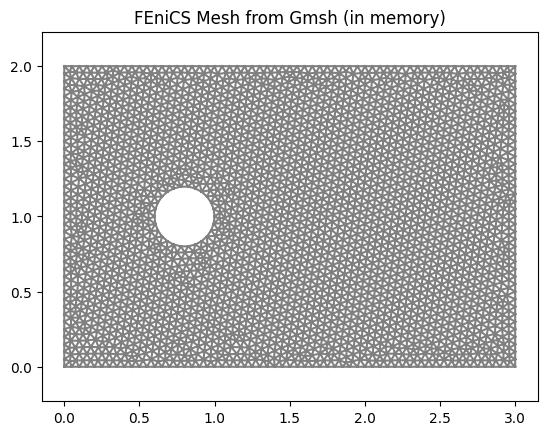

In [2]:
# Define rectangular domain
L = 3.0
H = 2.0

# Define circle
xc = 0.8
yc = 0.5*H
rc = 0.2

mesh_size = 0.05       # mesh size

gmsh.initialize()
gmsh.model.add("cylinder")

rect = gmsh.model.occ.addRectangle(0, 0, 0, L, H)
circle = gmsh.model.occ.addDisk(xc, yc, 0, rc, rc)

gmsh.model.occ.cut([(2, rect)], [(2, circle)])
gmsh.model.occ.synchronize()

gmsh.option.setNumber("Mesh.MeshSizeMax", mesh_size)

# note boundary
gmsh.model.addPhysicalGroup(2, [rect], name="domain")
boundaries = gmsh.model.getBoundary([(2, rect)], oriented=False)
boundary_lines = {}
curves = gmsh.model.getEntities(1)
tol = 1e-6
for curve in curves:
    dim, tag = curve
    bbox = gmsh.model.getBoundingBox(dim, tag)
    xmin, ymin, zmin, xmax, ymax, zmax = bbox
    
    if abs(ymin) < tol and abs(ymax) < tol:  # y≈0
        boundary_lines["bottom"] = tag
    elif abs(ymin - H) < tol and abs(ymax - H) < tol:  # y≈H
        boundary_lines["top"] = tag
    elif abs(xmin) < tol and abs(xmax) < tol:  # x≈0
        boundary_lines["left"] = tag
    elif abs(xmin - L) < tol and abs(xmax - L) < tol:  # x≈L
        boundary_lines["right"] = tag
    else:
        boundary_lines["hole"] = tag

boundnames = {"bottom": 2, "top": 3, "left": 4, "right": 5, "hole": 6}

for name, tag in boundary_lines.items():
    gmsh.model.addPhysicalGroup(1, [tag], name=name)

# generate 2D mesh
gmsh.model.mesh.generate(2)

node_tags, node_coords, _ = gmsh.model.mesh.get_nodes()
nodes = np.array(node_coords).reshape((-1, 3))[:, :2]  # 仅取 x, y

# Obtain triangle units
element_tags, node_tags = gmsh.model.mesh.get_elements_by_type(2)
cells = np.array(node_tags).reshape(-1, 3) - 1

physical_groups = {}
physicals = gmsh.model.getPhysicalGroups()
for dim, tag in physicals:
    name = gmsh.model.getPhysicalName(dim, tag)
    entities = gmsh.model.getEntitiesForPhysicalGroup(dim, tag)
    physical_groups[name] = {
        "tag": tag,
        "entities": list(entities)
    }

gmsh.finalize()

editor = MeshEditor()
mesh = Mesh()

editor.open(mesh, "triangle", 2, 2)
editor.init_vertices_global(nodes.shape[0], nodes.shape[0])
editor.init_cells_global(cells.shape[0], cells.shape[0])

for i, point in enumerate(nodes):
    editor.add_vertex(i, point)

for i, cell in enumerate(cells):
    editor.add_cell(i, cell)

editor.close()

# print("Number of vertices:", mesh.num_vertices())
# print("Number of cells:", mesh.num_cells())
plot(mesh)
plt.title("FEniCS Mesh from Gmsh (in memory)")
plt.axis("equal")
plt.show()

# 3. Define function space

In [3]:
V = VectorFunctionSpace(mesh,"P", 1)

# 4. Set boundary conditions

In [4]:
tol = 1E-6

def Bottom(x, on_boundary):
    return on_boundary and near(x[1], 0.0, tol)

def Top(x, on_boundary):
    return on_boundary and near(x[1], H, tol)

def Left(x, on_boundary):
    return on_boundary and near(x[0], 0.0, tol)

def Right(x, on_boundary):
    return on_boundary and near(x[0], L, tol)

def Cylinder(x, on_boundary):
    dist = sqrt((x[0] - xc)**2 + (x[1] - yc)**2)
    return on_boundary and near(dist, rc, 1e-2)

# 5. Define trial and test function

In [5]:
u = TrialFunction(V)
v = TestFunction(V)

u_n = Function(V)
u_mid = Function(V)

# 6. Define weak equation

In [6]:
# num_nnlin_iter = 5
# prec = "amg" if has_krylov_solver_preconditioner("amg") else "default"

alpha = 0.01
dt = (0.5*mesh.hmin()**2/alpha) * 0.1
T0 = 1
T1 = 4

u1 = Function(V)
u0 = interpolate(Expression(('T0', 0),T0=T0,H=H, degree=2), V)
u_n.assign(u0)

f = Constant((0, 0))
normal = FacetNormal(mesh)
cb = Expression("abs(sqrt((x[0] - xc)*(x[0] - xc) + (x[1] - yc)*(x[1] - yc)) - rc) < 0.01 ? 1. : 0.", xc=xc, yc=yc, rc=rc, degree=2)

theta = 0.5
u_mid = theta*u + (1-theta)*u_n

F = (
    inner((u - u_n)/dt, v)*dx
    + alpha*inner(grad(u_mid), grad(v))*dx
    - inner(f, v)*dx
    + cb * inner(grad(u) * normal, v) * ds
)

auv = lhs(F)
Lv = rhs(F)
print("Norm of auv is", assemble(auv).norm("frobenius"), ", Norm of Lv is", assemble(Lv).norm("l2"))

Norm of auv is 14.96099047282387 , Norm of Lv is 14.953133021263294


# 7. Computation

For diffusion equation:

$$
\frac{\partial {u}}{\partial t} - \alpha\nabla^2 u = 0
$$

the diffisive speed is $x \sim \sqrt{\alpha T}$. Therefore, to see the transport clearly, we need rather large $\alpha$.

In [7]:
def plotInnerU(j):
    plt.figure(figsize = (6,4))
    im = plot(inner(ulist[j], ulist[j]))
    plt.title("t = {}".format(j*dt))
    plt.colorbar(im)

def plotU(j):
    plt.figure(figsize = (6,4))
    im = plot(ulist[j])
    plt.title("t = {}".format(j*dt))
    plt.colorbar(im)

In [9]:
# file_u = File("results/u.pvd")

alpha = 0.01
#dt = (0.5*mesh.hmin()**2/alpha) * 0.1
dt = 0.5*mesh.hmin()

T = 10      
num_steps = int(T/dt)
#num_steps = int(200)

bcs = [DirichletBC(V, Expression(('T0*x[1]*(H-x[1])', 0),T0=T0,H=H, degree=2), Left),
    DirichletBC(V, Constant((0, 0)), Right),
    DirichletBC(V, Constant((0, 0)), Top),
    DirichletBC(V, Constant((0, 0)), Bottom),
#    DirichletBC(V, Expression(('T0', 0),T0=T0,H=H, degree=2), Cylinder),
]

ulist = [u0]
u0.rename("Velocity", "velocity field")

image_folder = './alpha_{}_T0_{}'.format(alpha, T0)
os.makedirs(image_folder, exist_ok = True)
# file_u << u0

for j in range(num_steps):
    
    A = assemble(auv)
    b = assemble(Lv)
    [bc.apply(A, b) for bc in bcs]
    [bc.apply(u1.vector()) for bc in bcs]
    solve(A, u1.vector(), b, "bicgstab", "default")
    u1.rename("Velocity", "velocity field")
    # file_u << u1
    ulist.append(Function(V))
    ulist[-1].assign(u1)
    u_n.assign(u1)

    plotInnerU(j)
    plt.savefig('./alpha_{}_T0_{}/u_{}.png'.format(alpha, T0, j))
    plt.close(1)
    process_bar(j+1,num_steps)

[****************************************************************************************************]100%

# 8. Postprocess

In [13]:
image_folder = './alpha_{}_T0_{}'.format(alpha, T0)
output_gif = 'alpha_{}_T0_{}.gif'.format(alpha, T0)

images = []
for j in range(num_steps):
    filename = './alpha_{}_T0_{}/u_{}.png'.format(alpha, T0, j)
    try:
        img = Image.open(filename)
        images.append(img)
    except FileNotFoundError:
        print(f"Warning: File {filename} doesn't exist, skip.")
        break

# Save as GIF
if images:
    images[0].save(
        output_gif,
        save_all=True,
        append_images=images[1:],
        duration=100,   # Display time per frame (milliseconds)
        loop=0,         # Number of loops, 0 means infinite loop
        disposal=2
    )
    print(f"GIF has been generated: {output_gif}")
else:
    print("No pictures for genrating GIF!")

GIF has been generated: alpha_0.01_T0_1.gif


# 9. Plot

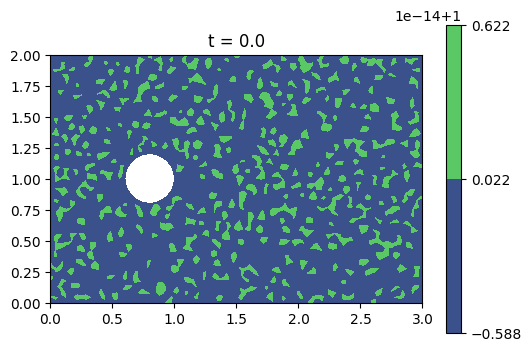

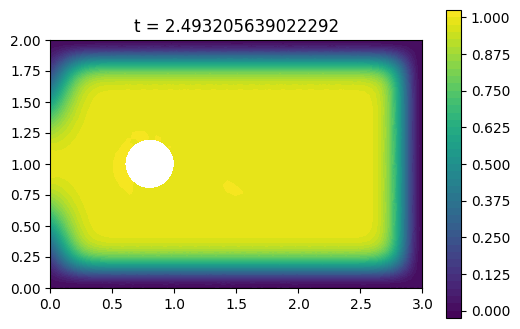

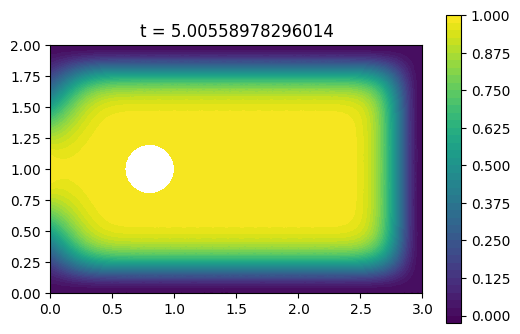

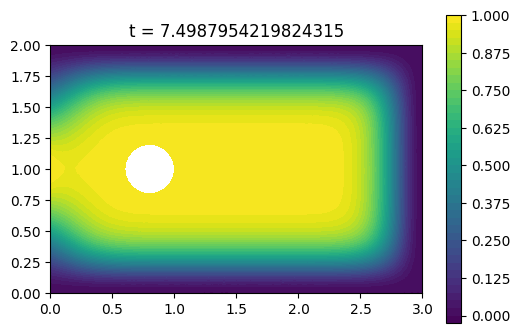

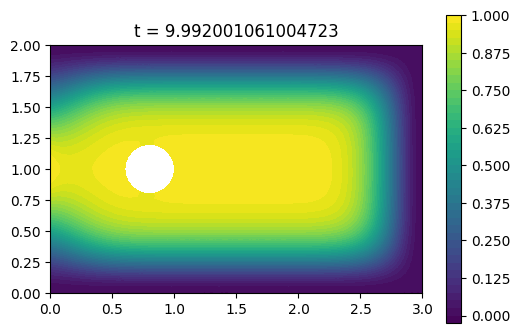

In [11]:
plotInnerU(0)
plotInnerU(int(len(ulist)*1/4))
plotInnerU(int(len(ulist)*2/4))
plotInnerU(int(len(ulist)*3/4))
plotInnerU(len(ulist)-1)

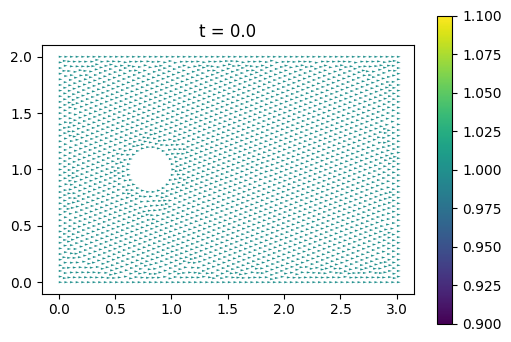

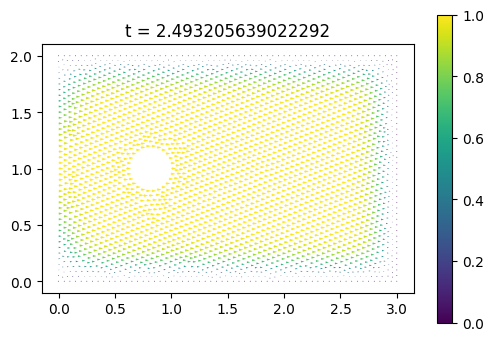

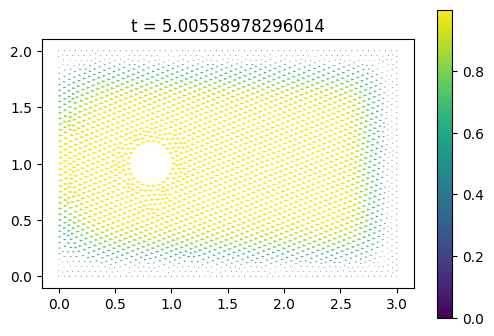

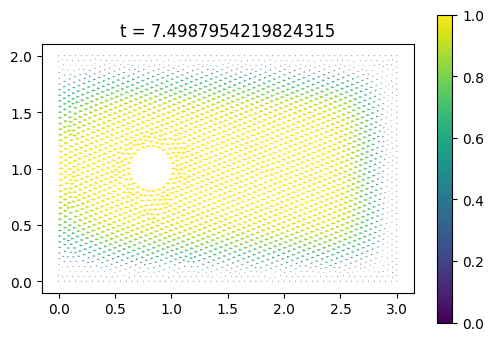

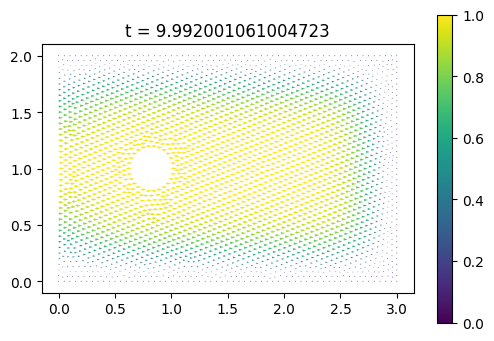

In [12]:
plotU(0)
plotU(int(len(ulist)*1/4))
plotU(int(len(ulist)*2/4))
plotU(int(len(ulist)*3/4))
plotU(len(ulist)-1)